# Introductionm

Every bank wants to hold there customers for sustaining their business and thus this Anonymous Multinational bank.
Below is the customer data of account holders at Anonymous Multinational Bank and the aim of the data will be predicting the Customer Churn.

This is the project description on Kaggle. We're going to analyze it from every angle to draw the best conclusions and make the best possible predictions.

In [41]:
import pandas as pd
import numpy as np
from nbformat.validator import normalize

df_cust = pd.read_csv("C:/Users/pc/Documents/kaggle_data/Customer-Churn-Records.csv", sep=',')
df_cust.shape

(10000, 10)

In [42]:
display(df_cust.head(10))

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts
0,1,15574012,Chu,645,Spain,Male,44,8,113755.78,2
1,2,15592531,Bartlett,822,France,Male,50,7,0.00,2
2,3,15656148,Obinna,376,Germany,Female,29,4,115046.74,4
3,4,15792365,He,501,France,Male,44,4,142051.07,2
4,5,15592389,H?,684,France,Male,27,2,134603.88,1
5,6,15634602,Hargrave,619,France,Female,42,2,0.00,1
6,7,15647311,Hill,608,Spain,Female,41,1,83807.86,1
7,8,15619304,Onio,502,France,Female,42,8,159660.80,3
8,9,15701354,Boni,699,France,Female,39,1,0.00,2
9,10,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1


In [43]:
df_cust.info(memory_usage='deep')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   RowNumber      10000 non-null  int64  
 1   CustomerId     10000 non-null  int64  
 2   Surname        10000 non-null  object 
 3   CreditScore    10000 non-null  int64  
 4   Geography      10000 non-null  object 
 5   Gender         10000 non-null  object 
 6   Age            10000 non-null  int64  
 7   Tenure         10000 non-null  int64  
 8   Balance        10000 non-null  float64
 9   NumOfProducts  10000 non-null  int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 2.1 MB


In [44]:
# Verifye valè ki manke yo
missing = pd.DataFrame({
    "missing_count": df_cust.isna().sum(),
    "missing_percent": df_cust.isna().mean() * 100
})

display(
    missing.sort_values(
        "missing_percent",
        ascending=False
    )
)

,missing_count,missing_percent
RowNumber,0,0.0
CustomerId,0,0.0
Surname,0,0.0
CreditScore,0,0.0
Geography,0,0.0
Gender,0,0.0
Age,0,0.0
Tenure,0,0.0
Balance,0,0.0
NumOfProducts,0,0.0


In [45]:
# Nombre de doublons
print("Duplicate lines:", df_cust.duplicated().sum())

# Valeurs distinctes par colonne
display(
    df_cust.nunique(dropna=False)
    .sort_values(ascending=False)
    .to_frame("unique_values")
)

Duplicate lines: 0


,unique_values
RowNumber,10000
CustomerId,10000
Balance,6382
Surname,2932
CreditScore,460
Age,70
Tenure,11
NumOfProducts,4
Geography,3
Gender,2


In [46]:
# Statistiques des colonnes numériques
display(df_cust.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0


In [47]:
# Pour analyser plus en detail le comportement des clients on va les catégoriser par genre et par pays
df_cust['Gender_num'] = df_cust['Gender'].map({'Female': 0, 'Male': 1})
df_cust['Geography_num'] = df_cust['Geography'].map({'France': 0, 'Spain': 1, 'Germany': 2})

print(df_cust.head(10))

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15574012       Chu          645     Spain    Male   44   
1          2    15592531  Bartlett          822    France    Male   50   
2          3    15656148    Obinna          376   Germany  Female   29   
3          4    15792365        He          501    France    Male   44   
4          5    15592389        H?          684    France    Male   27   
5          6    15634602  Hargrave          619    France  Female   42   
6          7    15647311      Hill          608     Spain  Female   41   
7          8    15619304      Onio          502    France  Female   42   
8          9    15701354      Boni          699    France  Female   39   
9         10    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  Gender_num  Geography_num  
0       8  113755.78              2           1              1  
1       7       0.00              2           1        

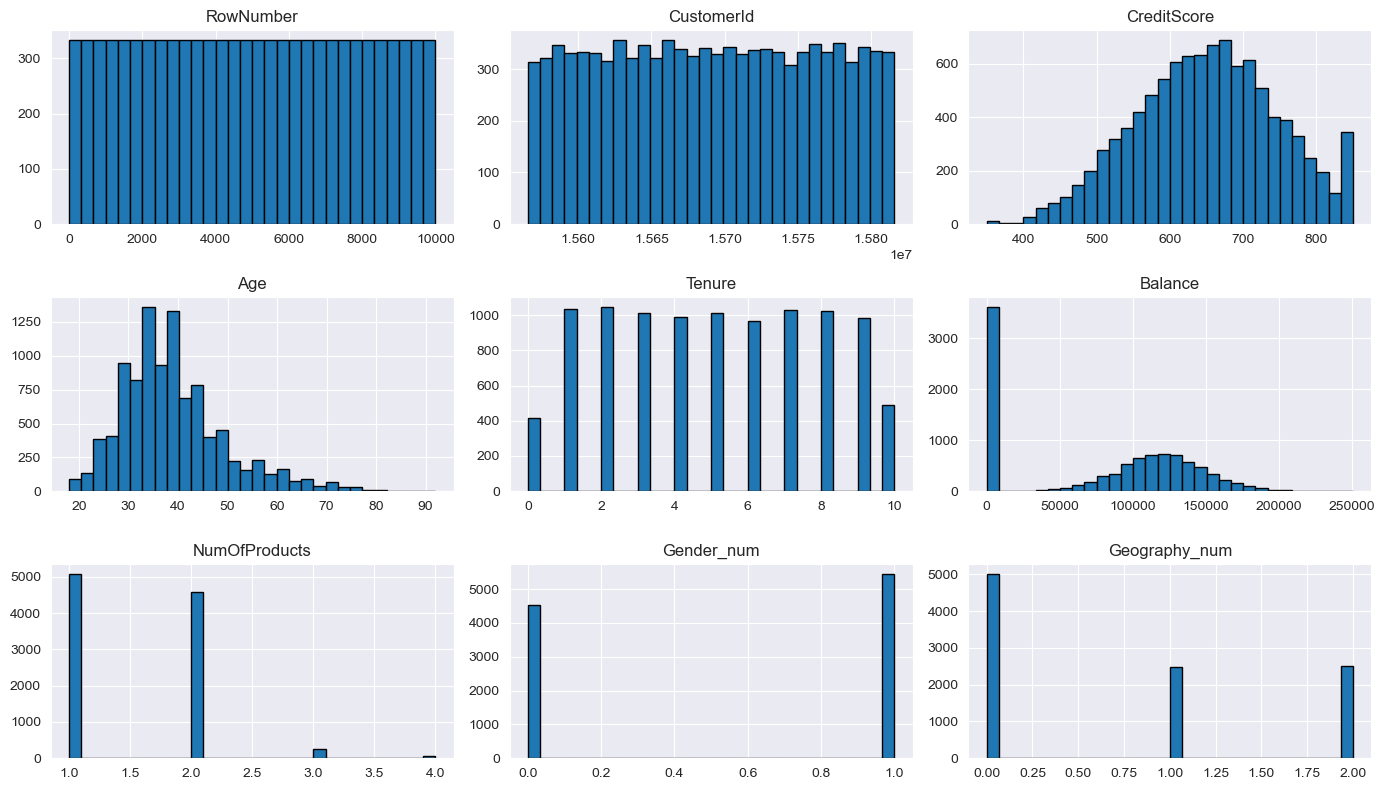

In [48]:
# Visualise les distibutions
import matplotlib.pyplot as plt

# Selectionner les colonnes numériques
numeric_df = df_cust.select_dtypes(include="number")

# Histogrammes des premières variables numériques
numeric_df.hist(
    bins=30,
    figsize=(14, 8),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

<Axes: >

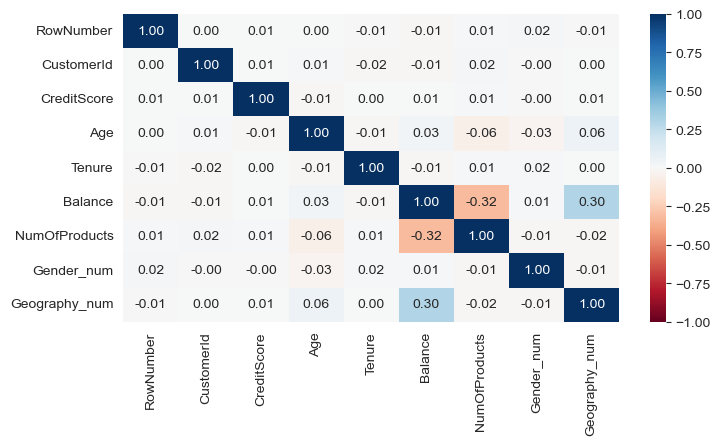

In [49]:
# Corrélation entre variables numériques
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(numeric_df.corr(method="spearman"), annot=True, cmap="RdBu", ax=ax, fmt=".2f", vmin=-1,
            vmax=1)


        tenure_count  tenure_percent
Tenure                              
0                413            4.13
1               1035           10.35
2               1048           10.48
3               1009           10.09
4                989            9.89
5               1012           10.12
6                967            9.67
7               1028           10.28
8               1025           10.25
9                984            9.84
10               490            4.90


C:\Users\pc\AppData\Local\Temp\ipykernel_5512\423830586.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tenure_dist.index, y=tenure_dist['tenure_count'], palette="Blues_d", legend=False )


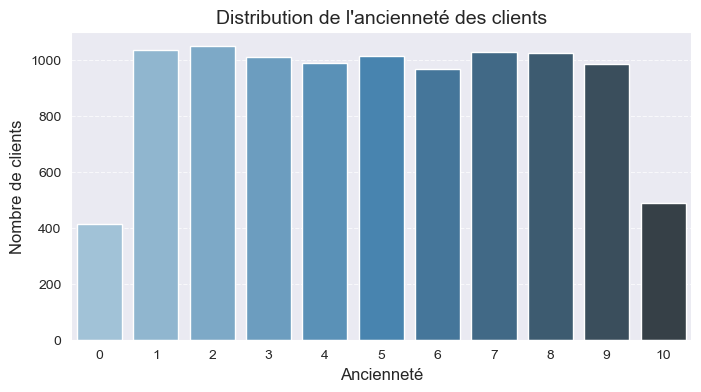

In [50]:
# distributions de l'encienneté
tenure_dist = pd.DataFrame({
    "tenure_count": df_cust['Tenure'].value_counts().sort_index(),
    "tenure_percent": df_cust['Tenure'].value_counts(normalize=True).sort_index() * 100
})


print(tenure_dist)

plt.figure(figsize=(8, 4))
sns.barplot(x=tenure_dist.index, y=tenure_dist['tenure_count'], palette="Blues_d", legend=False )
plt.title("Distribution de l'ancienneté des clients", fontsize=14)
plt.xlabel("Ancienneté", fontsize=12)
plt.ylabel("Nombre de clients", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [51]:
# Comptage de la tenure des cients par pays et par sexe
tenure_gender_dist = pd.crosstab(index=df_cust['Tenure'], columns=[df_cust['Geography'], df_cust['Gender']])
print(tenure_gender_dist)

# En pourcentage
tenure_gender_pct = pd.crosstab(index=df_cust['Tenure'], columns=[df_cust['Geography'], df_cust['Gender']],
                                normalize='index') * 100
print(tenure_gender_pct)



Geography France      Germany       Spain     
Gender    Female Male  Female Male Female Male
Tenure                                        
0            104  101      56   49     44   59
1            231  298     137  127    110  132
2            246  279     129  146    105  143
3            233  258     121  140    115  142
4            230  282     104  128    108  137
5            203  282     122  137    123  145
6            238  265     106  121    114  123
7            247  305     108  117    109  142
8            196  269     119  145    118  178
9            220  284     114  155     88  123
10           113  130      77   51     55   64
Geography     France               Germany                 Spain           
Gender        Female       Male     Female       Male     Female       Male
Tenure                                                                     
0          25.181598  24.455206  13.559322  11.864407  10.653753  14.285714
1          22.318841  28.792271  13.23

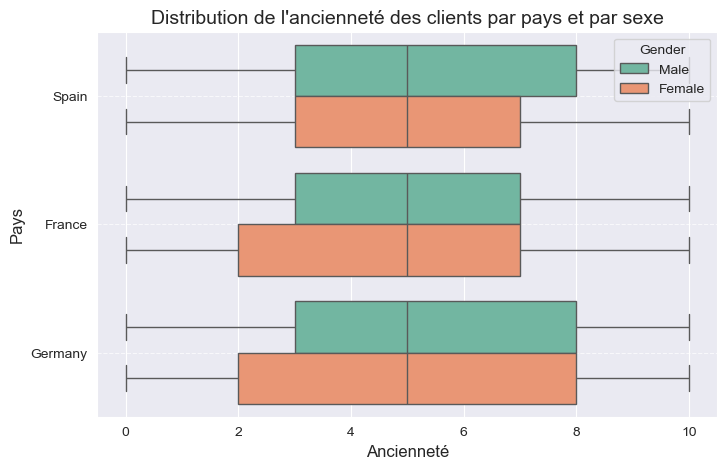

In [53]:
# Visualisation
plt.figure(figsize=(8, 5))
sns.boxplot(x=df_cust['Tenure'], y=df_cust['Geography'], hue=df_cust['Gender'], palette='Set2')
plt.title("Distribution de l'ancienneté des clients par pays et par sexe", fontsize=14)
plt.xlabel("Ancienneté", fontsize=12)
plt.ylabel("Pays", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Gender       Female      Male
Geography                    
France     4.950022  5.049401
Germany    4.965633  5.050152
Spain      5.000000  5.057637


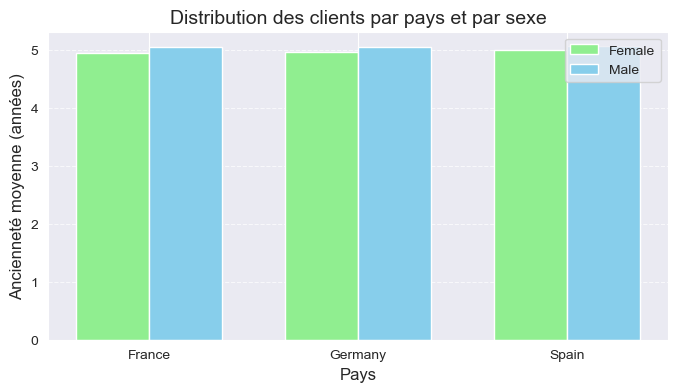

In [83]:
# Calculer la tenure moyenne par pays et par sexe
tenure_mean_by_geo_gender = df_cust.groupby(['Geography', 'Gender'])['Tenure'].mean().unstack()
print(tenure_mean_by_geo_gender)

# Graphique en barres groupées
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(tenure_mean_by_geo_gender.index))
width = 0.35

r1 = ax.bar(x - width/2, tenure_mean_by_geo_gender['Female'], width, label='Female', color='lightGreen')
r2 = ax.bar(x + width/2, tenure_mean_by_geo_gender['Male'], width, label='Male', color='skyblue')

ax.set_xticks(x)
ax.set_xticklabels(tenure_mean_by_geo_gender.index)
ax.set_title("Distribution des clients par pays et par sexe", fontsize=14)
ax.set_xlabel("Pays", fontsize=12)
ax.set_ylabel("Ancienneté moyenne (années)", fontsize=12)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()